# 04 — Optimize and evaluate

The recorded baseline comparison selected Logistic Regression and Gradient Boosting for tuning. Choose using training CV, then evaluate the independent test set.

Open from the notebooks folder. Saved outputs are from the earlier execution; the simplified source has not been rerun in full.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import joblib
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

numeric_columns = [
    'Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
    'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
    'Family_Support', 'Attendance_Rate',
]
categorical_columns = [
    'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
    'Previous_Mental_Health_History',
]

## Split the data

In [2]:
df = pd.read_csv('../data/raw/student_mental_health.csv')
X = df[numeric_columns + categorical_columns]
y = df['Mental_Health_Risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Preprocessing

GridSearchCV fits a fresh copy of preprocessing inside each training fold.

In [3]:
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [4]:
logistic_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
logistic_grid = {'model__C': [0.1, 1., 10.], 'model__class_weight': [None, 'balanced']}
logistic_search = GridSearchCV(logistic_model, logistic_grid, scoring='f1_macro', cv=cv)
logistic_search.fit(X_train, y_train)
print(logistic_search.best_params_)
print(logistic_search.best_score_)

boosting_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, early_stopping=False, random_state=42)),
])
boosting_grid = {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [7, 15], 'model__l2_regularization': [0., 1.]}
boosting_search = GridSearchCV(boosting_model, boosting_grid, scoring='f1_macro', cv=cv)
boosting_search.fit(X_train, y_train)
print(boosting_search.best_params_)
print(boosting_search.best_score_)

{'model__C': 1.0, 'model__class_weight': 'balanced'}
0.750216293167733
{'model__l2_regularization': 0.0, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15}
0.6950230165909668


## Choose and save the best model

Use the higher training CV score. The test set has not been used for selection.

In [5]:
if logistic_search.best_score_ >= boosting_search.best_score_:
    best_pipeline = logistic_search.best_estimator_
    selected_name = 'Logistic Regression'
else:
    best_pipeline = boosting_search.best_estimator_
    selected_name = 'Gradient Boosting'

Path('../models/notebooks').mkdir(exist_ok=True)
joblib.dump(best_pipeline, '../models/notebooks/best_pipeline.joblib', compress=3)
numeric_pipeline = best_pipeline.named_steps['preprocess'].named_transformers_['numeric']
joblib.dump(numeric_pipeline.named_steps['scale'], '../models/notebooks/scaler.joblib', compress=3)
print(selected_name)

Logistic Regression


## Test metrics

Evaluate after selection. Do not retune after reviewing these scores.

In [6]:
predictions = best_pipeline.predict(X_test)
probabilities = best_pipeline.predict_proba(X_test)
scores = {
    'accuracy': accuracy_score(y_test, predictions),
    'precision_macro': precision_score(y_test, predictions, average='macro', zero_division=0),
    'recall_macro': recall_score(y_test, predictions, average='macro', zero_division=0),
    'f1_macro': f1_score(y_test, predictions, average='macro', zero_division=0),
    'f1_weighted': f1_score(y_test, predictions, average='weighted', zero_division=0),
    'roc_auc_ovr': roc_auc_score(y_test, probabilities, labels=best_pipeline.classes_, multi_class='ovr'),
    'recall_high': recall_score(y_test, predictions, labels=['High'], average='macro'),
}
test_metrics = pd.DataFrame([scores])
display(test_metrics)
test_metrics.to_csv('../models/notebooks/test_metrics.csv', index=False)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,recall_high
0,0.755,0.753992,0.754308,0.754128,0.754762,0.913919,0.823529


## Classification report and confusion matrix

              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.81      0.81       132
      Medium       0.63      0.63      0.63       132

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.76      0.75       400



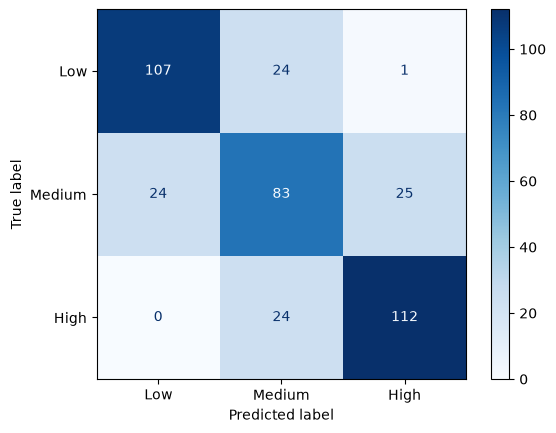

In [7]:
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=['Low', 'Medium', 'High'], cmap='Blues')
plt.show()

## ROC curves

These curves show ranking ability, not clinical validity or calibrated medical probabilities.

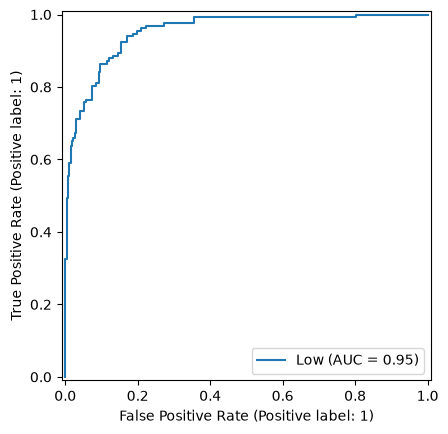

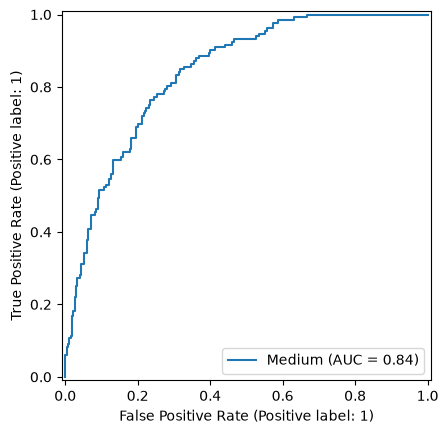

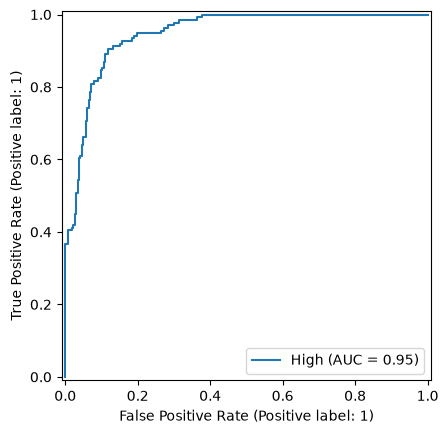

In [8]:
for label in ['Low', 'Medium', 'High']:
    column = list(best_pipeline.classes_).index(label)
    RocCurveDisplay.from_predictions(y_test == label, probabilities[:, column], name=label)
    plt.show()

## Prediction errors

In [9]:
examples = X_test.copy()
examples['Actual'] = y_test
examples['Prediction'] = predictions
errors = examples[examples['Actual'] != examples['Prediction']]
print('Incorrect predictions:', len(errors))
display(errors.head(8))

Incorrect predictions: 98


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Prediction
720,22,4,5.9,21.7,2.23,6.1,9.0,3.1,9.4,86.5,Female,Moderate,Yes,Poor,No,Low,Medium
1624,25,1,6.9,19.7,2.35,6.4,8.8,6.8,7.2,75.3,Male,Low,Yes,Poor,No,Medium,High
1854,23,1,7.8,4.9,2.15,6.3,9.9,6.1,5.9,78.7,Male,Low,Yes,Good,No,High,Medium
1130,22,3,8.4,18.5,2.47,5.8,8.1,3.0,3.4,75.7,Female,High,No,Poor,No,Medium,Low
1071,22,1,6.1,17.9,2.22,5.5,8.7,2.4,7.7,87.9,Male,High,Yes,Average,No,Medium,Low
1522,21,5,6.5,22.5,2.38,NaN,7.9,6.5,8.8,84.7,Male,High,No,Average,No,Medium,Low
911,21,5,6.3,25.6,2.60,6.9,8.3,4.6,6.2,84.5,Female,Moderate,No,Good,No,Medium,Low
1887,22,3,6.2,15.1,2.64,8.0,10.5,4.3,4.8,82.1,Male,Low,No,Average,No,Medium,High


## Which labels are confused?

Count the mistaken label pairs. Small subgroup results cannot establish fairness.

In [10]:
display(errors[['Actual', 'Prediction']].value_counts())

Actual  Prediction
Medium  High          25
Low     Medium        24
High    Medium        24
Medium  Low           24
Low     High           1
Name: count, dtype: int64

## Reload the saved model

The full pipeline already includes scaling, so do not apply the separate scaler again.

In [11]:
saved_model = joblib.load('../models/notebooks/best_pipeline.joblib')
print(saved_model.predict(X_test.head(3)))

['High' 'Medium' 'Medium']


## Results and limits

The data is synthetic. Missing answers, overlapping labels and one fixed test set limit what these scores demonstrate. No medical conclusions can be drawn.

In [12]:
print('Selected model:', selected_name)
display(test_metrics)

Selected model: Logistic Regression


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,recall_high
0,0.755,0.753992,0.754308,0.754128,0.754762,0.913919,0.823529
